# UTS Graf Sains Data

Nama : Brilliyanda Annisaatulrohmah

NIM : 23031554216

Kelas : 2023E

Mata Kuliah : Graf Sains Data

Fold training: 2015-05-29 s.d. 2015-08-17 | Fold testing: 2015-08-18 s.d. 2015-09-07 (batas inklusif, zona waktu UTC).

Prasyarat (terminal, sekali saja): venv aktif, uv pip install -r requirements.txt, server Neo4j 5.x jalan, data/events.csv ada.
1. Hanya fold training yang diimpor ke graf (fold testing disimpan di CSV untuk evaluasi). Memasukkan testing ke graf = data leakage.
2. Bobot implisit: VIEWED=1, ADDED_TO_CART=3, BOUGHT=5 (konvensi, bukan aturan baku).
3. Similarity = cosine pada vektor ter-normalisasi L2.

In [ ]:
import os, math, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, networkx as nx
from scipy.sparse import csr_matrix
from sklearn.preprocessing import normalize
from tqdm.auto import tqdm
from neo4j import GraphDatabase

DATA_DIR = "D:/UTS_Graf Sada/data/ecommerce-dataset"
URI, DB = "bolt://127.0.0.1:7687", "neo4j"
AUTH = ("neo4j", os.environ.get("NEO4J_PASSWORD", "utsgrafsada"))   
TRAIN = ("2015-05-29", "2015-08-17")   # inklusif
TEST  = ("2015-08-18", "2015-09-07")   # inklusif
SEED, BATCH = 42, 50_000
W = {"VIEWED": 1, "ADDED_TO_CART": 3, "BOUGHT": 5}

Pendukung proses analisis
1. Mengimpor library yang dipakai: os untuk environment/path, math untuk pembulatan dan logaritma, json untuk kebutuhan struktur data, NumPy/Pandas untuk pengolahan data, Matplotlib untuk visualisasi, NetworkX untuk graf, scipy.sparse untuk matriks sparse, sklearn.normalize untuk normalisasi L2, tqdm untuk progress bar, dan GraphDatabase untuk koneksi Neo4j.
2. DATA_DIR menentukan lokasi events.csv.
3. URI dan DB menentukan alamat Bolt dan nama database Neo4j.
4. AUTH mengambil password dari environment variable NEO4J_PASSWORD; jika tidak ada, notebook memakai nilai default yang ditulis di sini. Untuk keamanan, password asli sebaiknya tidak disimpan di notebook.
5. TRAIN dan TEST menetapkan dua periode yang berbeda sesuai soal 2.1 nomor 1. Training: 29 Mei–17 Agustus 2015; testing: 18 Agustus–7 September 2015. Batas tanggal dibuat inklusif.
6. SEED=42 membuat proses acak dapat direproduksi, sedangkan BATCH=50.000 menentukan jumlah baris per batch saat impor.
7. W menetapkan bobot interaksi implisit: VIEWED=1, ADDED_TO_CART=3, BOUGHT=5. Ini adalah asumsi desain notebook, bukan aturan baku dataset.

## A. EDA data mentah 

shape: (2756101, 6) | rentang: 2015-05-03 03:00:04.384000+00:00 -> 2015-09-18 02:59:47.788000+00:00
timestamp              0
visitorid              0
event                  0
itemid                 0
transactionid    2733644
ts                     0
dtype: int64 

event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64 

visitor unik: 1407580 | item unik: 235061
transactionid terisi == jumlah event transaction: True


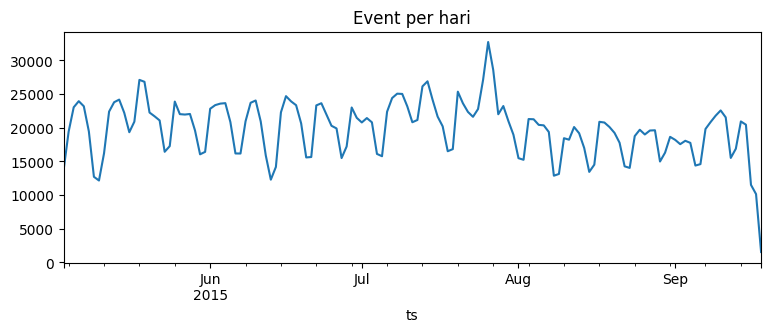

In [14]:
raw = pd.read_csv(f"{DATA_DIR}/events.csv", dtype={"transactionid": "Int64"})
raw["ts"] = pd.to_datetime(raw["timestamp"], unit="ms", utc=True)   # timestamp = milidetik
print("shape:", raw.shape, "| rentang:", raw.ts.min(), "->", raw.ts.max())
print(raw.isna().sum(), "\n")
print(raw.event.value_counts(), "\n")
print("visitor unik:", raw.visitorid.nunique(), "| item unik:", raw.itemid.nunique())
print("transactionid terisi == jumlah event transaction:",
      raw.transactionid.notna().sum() == (raw.event == "transaction").sum())
raw.set_index("ts").resample("D").size().plot(figsize=(9, 3), title="Event per hari"); plt.show()

EDA awal / persiapan data
1. Membaca events.csv menjadi DataFrame. transactionid menggunakan nullable integer agar nilai kosong tetap dapat ditangani.
2. Mengubah timestamp Unix dalam milidetik menjadi datetime UTC sehingga filter periode dapat dilakukan dengan benar.
3. Menampilkan ukuran data dan rentang waktunya sebagai EDA awal.
4. Menghitung jumlah nilai kosong setiap kolom untuk mengetahui kualitas data.
5. Menghitung frekuensi tiap jenis event: view, addtocart, dan transaction.
6. Menghitung jumlah visitor dan item unik.
7. Memeriksa konsistensi: jumlah transactionid yang terisi harus sama dengan jumlah event transaction.
8. Meresampling event per hari dan membuat grafik untuk melihat pola volume interaksi sepanjang waktu.

## B. Filter periode, simpan CSV (soal 2.1 no. 1-2)

1. Tentukan 2 periode waktu sebagai filter dari data interaksi. Kombinasi periode yang dipilih tiap mahasiswa
tidak boleh sama! (akan ditentukan)
Misal: Fold training (P1) → 01/2023 - 03/2023; Fold testing (P2) 01/2024 - 06/2024.
2. Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv!

In [15]:
def cut(df, start, end_inclusive):
    s = pd.Timestamp(start, tz="UTC")
    e = pd.Timestamp(end_inclusive, tz="UTC") + pd.Timedelta(days=1)   # [start, end+1 hari)
    return df[(df.ts >= s) & (df.ts < e)]

train, test = cut(raw, *TRAIN), cut(raw, *TEST)
assert len(train) and len(test) and train.ts.max() < test.ts.min()
train.drop(columns="ts").to_csv(f"{DATA_DIR}/events_train.csv", index=False)
test.drop(columns="ts").to_csv(f"{DATA_DIR}/events_test.csv", index=False)

summ = pd.DataFrame({n: {"baris": len(d), "visitor": d.visitorid.nunique(), "item": d.itemid.nunique(),
                         **d.event.value_counts().to_dict()} for n, d in [("train", train), ("test", test)]})
print(summ)
print("proporsi visitor test yang ada di train:", len(set(train.visitorid) & set(test.visitorid)) / test.visitorid.nunique())
print("proporsi item test yang ada di train   :", len(set(train.itemid) & set(test.itemid)) / test.itemid.nunique())

               train    test
baris        1661237  372726
visitor       862832  211108
item          189380   92561
view         1605906  359734
addtocart      41756    9800
transaction    13575    3192
proporsi visitor test yang ada di train: 0.07993538852151505
proporsi item test yang ada di train   : 0.8015254804939446


Notebook menampilkan rentang waktu, nilai null, dan distribusi event, lalu memfilter:
- Train: 2015-05-29 s.d. 2015-08-17.
- Test: 2015-08-18 s.d. 2015-09-07.
- Batas akhir dibuat inklusif, jadi filter memakai < tanggal_akhir + 1 hari.
- Hasilnya disimpan ke events_train.csv dan events_test.csv.

Output menampilkan ringkasan jumlah baris, visitor unik, item unik, dan komposisi event pada training dan testing.

## C. Koneksi Neo4j, constraint, reset, impor fold training

In [16]:
# [DB]
driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()

def q(cypher, **params):
    """Jalankan Cypher, kembalikan DataFrame."""
    return driver.execute_query(cypher, params, database_=DB, result_transformer_=lambda r: r.to_df())

In [17]:
# [DB]
RESET = True   # hapus graf lama agar impor ulang tidak menduplikasi relasi (CREATE tidak idempoten)
with driver.session(database=DB) as s:
    if RESET:
        while s.run("MATCH (n) WITH n LIMIT 10000 DETACH DELETE n RETURN count(*) AS c").single()["c"] > 0:
            pass
    s.run("CREATE CONSTRAINT v_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE").consume()
    s.run("CREATE CONSTRAINT i_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE").consume()

In [18]:
# [DB]
HEAD = "UNWIND $rows AS r MERGE (v:Visitor {visitorId: r.v}) MERGE (i:Item {itemId: r.i}) "
IMPORT_Q = {
    "view":        HEAD + "CREATE (v)-[:VIEWED {timestamp: r.t}]->(i)",
    "addtocart":   HEAD + "CREATE (v)-[:ADDED_TO_CART {timestamp: r.t}]->(i)",
    "transaction": HEAD + "CREATE (v)-[:BOUGHT {timestamp: r.t, transactionId: r.tx}]->(i)",
}

def import_batch(tx, chunk):
    for ev, g in chunk.groupby("event"):
        if ev not in IMPORT_Q:
            continue
        rows = [{"v": int(v), "i": int(i), "t": int(t), "tx": None if pd.isna(x) else int(x)}
                for v, i, t, x in zip(g.visitorid, g.itemid, g.timestamp, g.transactionid)]
        tx.run(IMPORT_Q[ev], rows=rows)

chunks = pd.read_csv(f"{DATA_DIR}/events_train.csv", chunksize=BATCH, dtype={"transactionid": "Int64"})
with driver.session(database=DB) as s:
    for ch in tqdm(chunks, total=math.ceil(len(train) / BATCH), desc="Impor batch"):
        s.execute_write(import_batch, ch)
print("Impor selesai.")

Impor batch:   0%|          | 0/34 [00:00<?, ?it/s]

Impor selesai.


Hanya fold training yang diimpor. Konstrain dibuat, graf lama dihapus (agar tidak ada relasi ganda), lalu data diimpor per batch 50.000 baris. Setelah impor ada assert yang membandingkan jumlah relasi di graf dengan jumlah baris train.

## D. Komposisi subgraph (soal 2.1 no. 3)
3. Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah
masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!

In [19]:
# [DB]
nodes_df = q("MATCH (n) RETURN labels(n)[0] AS label, count(*) AS jumlah ORDER BY jumlah DESC")
rels_df  = q("MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah ORDER BY jumlah DESC")
pat_df   = q("""MATCH (v:Visitor)-[r]->(i:Item)
                RETURN type(r) AS relasi, count(DISTINCT v) AS visitor, count(DISTINCT i) AS item, count(*) AS relasi_total""")
print(nodes_df, "\n\n", rels_df, "\n\n", pat_df)
# Validasi: jumlah relasi di graf harus sama dengan jumlah baris train
assert rels_df.jumlah.sum() == len(train), "Jumlah relasi != baris train, cek impor"

     label  jumlah
0  Visitor  862832
1     Item  189380 

           relasi   jumlah
0         VIEWED  1605906
1  ADDED_TO_CART    41756
2         BOUGHT    13575 

           relasi  visitor    item  relasi_total
0  ADDED_TO_CART    22816   16830         41756
1         BOUGHT     7064    8114         13575
2         VIEWED   860865  189196       1605906


Tiga query Cypher menghitung simpul per label, relasi per tipe, serta visitor dan item distinct per tipe relasi.
- `MATCH (n)` mengambil semua simpul; `labels(n)[0]` = label; `count(*)` dengan pengelompokan implisit per label.
- `MATCH ()-[r]->()` mengambil semua relasi; `type(r)` = tipe relasi.
- Pola terakhir menghitung visitor dan item **distinct** per tipe relasi.


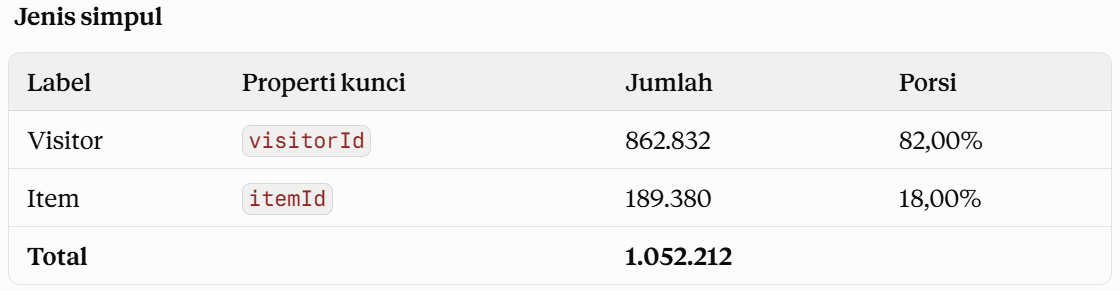

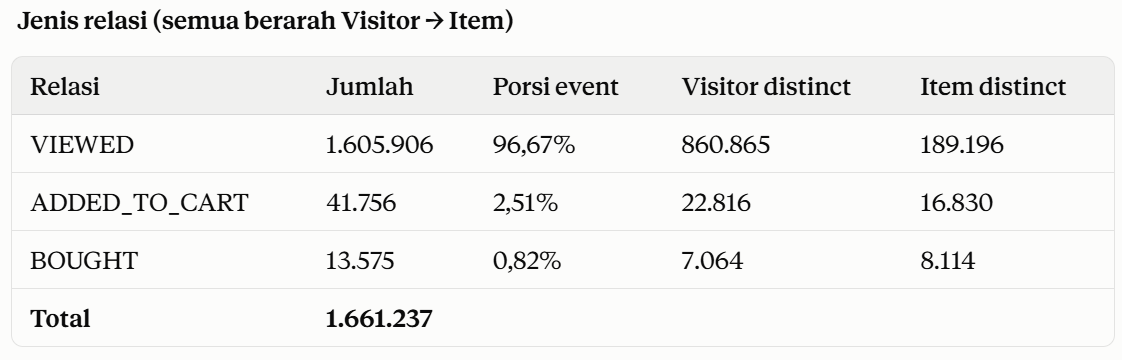

Bentuk graf: bipartit berarah dengan 2 jenis simpul dan 3 jenis relasi. Rata-rata ada 1,93 relasi per visitor (1.661.237 / 862.832) dan 8,77 relasi per item.

## E. VSM User dan Item (soal 2.1 no. 4-5)
4. Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana
karakteristiknya (dimensi, shape, plot networkx, dst.)!
5. Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (dimensi,
shape, plot networkx, dst.)!

Matriks interaksi user x item dibaca dari graf (agregasi dilakukan di Neo4j), bobot = bobot tipe x jumlah kejadian.

In [20]:
# [DB]
edges = q("MATCH (v:Visitor)-[r]->(i:Item) RETURN v.visitorId AS u, i.itemId AS i, type(r) AS t, count(*) AS c")

VSM User : tiap user = vektor 189380 dimensi (item) -> shape (862832, 189380)
VSM Item : tiap item = vektor 862832 dimensi (user) -> shape (189380, 862832)
nnz=1296043 | density=7.932e-06 | memori sparse=19.0 MB | dense setara=1307.2 GB
derajat user:
 count    862832.000000
mean          1.502080
std           6.616294
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max        3257.000000
dtype: float64 
user dengan 1 item: 80.4%
derajat item:
 count    189380.000000
mean          6.843611
std          18.677202
min           1.000000
25%           1.000000
50%           2.000000
75%           6.000000
max        1853.000000
dtype: float64 
item dengan 1 user: 38.6%


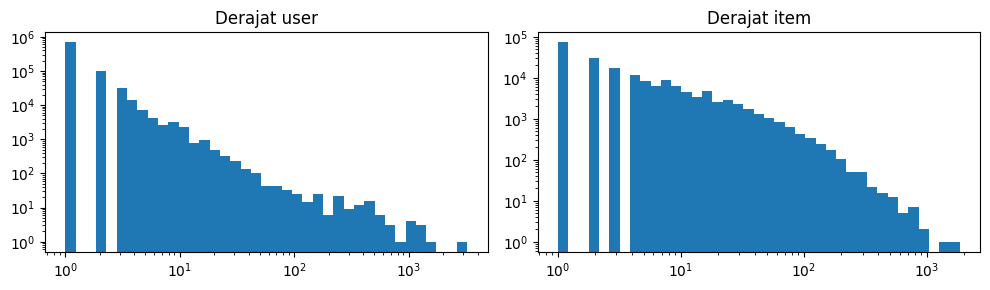

In [21]:
edges["w"] = edges.t.map(W) * edges.c
d = edges.groupby(["u", "i"], as_index=False).w.sum()
users, items = np.sort(d.u.unique()), np.sort(d.i.unique())
M = csr_matrix((d.w.astype(float).values,
                (pd.Index(users).get_indexer(d.u), pd.Index(items).get_indexer(d.i))),
               shape=(len(users), len(items)))
Mc = M.tocsc()
du = np.diff(M.indptr).astype(np.int64)    # derajat user = jumlah item distinct
di = np.diff(Mc.indptr).astype(np.int64)   # derajat item = jumlah user distinct

mb = lambda A: (A.data.nbytes + A.indices.nbytes + A.indptr.nbytes) / 1e6
print(f"VSM User : tiap user = vektor {M.shape[1]} dimensi (item) -> shape {M.shape}")
print(f"VSM Item : tiap item = vektor {M.shape[0]} dimensi (user) -> shape {M.T.shape}")
print(f"nnz={M.nnz} | density={M.nnz / (M.shape[0] * M.shape[1]):.3e} | memori sparse={mb(M):.1f} MB | dense setara={M.shape[0] * M.shape[1] * 8 / 1e9:.1f} GB")
print("derajat user:\n", pd.Series(du).describe(), f"\nuser dengan 1 item: {(du == 1).mean():.1%}")
print("derajat item:\n", pd.Series(di).describe(), f"\nitem dengan 1 user: {(di == 1).mean():.1%}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(du, bins=np.logspace(0, np.log10(du.max() + 1), 40)); ax[0].set(xscale="log", yscale="log", title="Derajat user")
ax[1].hist(di, bins=np.logspace(0, np.log10(di.max() + 1), 40)); ax[1].set(xscale="log", yscale="log", title="Derajat item")
plt.tight_layout(); plt.show()

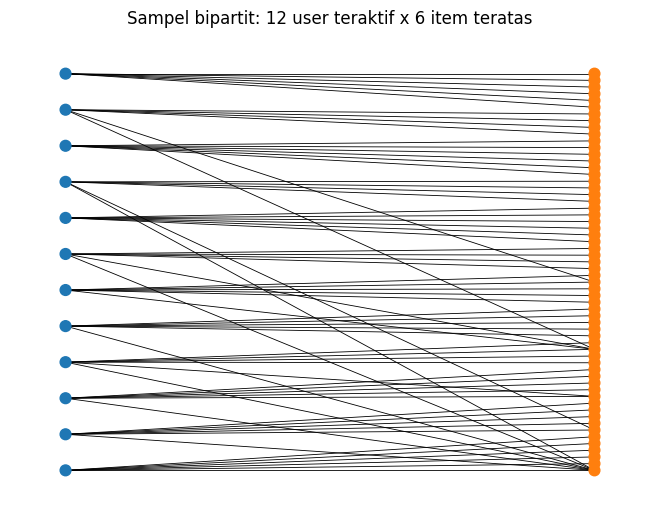

In [22]:
# Plot networkx pada SAMPEL (plot seluruh graf tidak terbaca). Prefix u/i karena ID user dan item bisa bertabrakan.
rng = np.random.default_rng(SEED)
top_u = np.argsort(-np.asarray(M.sum(axis=1)).ravel(), kind="stable")[:12]
G, U = nx.Graph(), []
for ui_ in top_u:
    row = M.getrow(ui_); top_i = row.indices[np.argsort(-row.data, kind="stable")[:6]]
    U.append(f"u{users[ui_]}")
    G.add_edges_from((f"u{users[ui_]}", f"i{items[j]}") for j in top_i)
pos = nx.bipartite_layout(G, U)
col = ["tab:blue" if n.startswith("u") else "tab:orange" for n in G]
nx.draw(G, pos, node_color=col, node_size=60, width=0.6); plt.title("Sampel bipartit: 12 user teraktif x 6 item teratas"); plt.show()

Matriks user × item dibaca dari graf dengan bobot view=1, addtocart=3, transaction=5. Notebook melaporkan shape, density, memori, distribusi derajat, dan plot networkx pada sampel (bukan seluruh graf). Perbandingan proyeksi dihitung dari jumlah pasangan Σ C(deg,2) tanpa membentuk matriks.

## F. Proyeksi mana yang lebih baik (soal 2.1 no. 6)
6. Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!

Biaya proyeksi diestimasi dari derajat, **tanpa** membentuk matriks: jumlah pasangan yang berbagi tetangga = sum C(deg, 2).

In [23]:
pairs_uu = int((di * (di - 1) // 2).sum())   # pasangan user lewat item bersama (batas atas nnz proyeksi user-user)
pairs_ii = int((du * (du - 1) // 2).sum())   # pasangan item lewat user bersama (batas atas nnz proyeksi item-item)
cmp_ = pd.DataFrame({"user-user": {"simpul": M.shape[0], "matriks_penuh_n^2": M.shape[0] ** 2, "pasangan_bersama(batas atas nnz)": pairs_uu},
                     "item-item": {"simpul": M.shape[1], "matriks_penuh_n^2": M.shape[1] ** 2, "pasangan_bersama(batas atas nnz)": pairs_ii}})
print(cmp_.astype(object).apply(lambda c: c.map("{:,}".format)))
# Tulis kesimpulan HANYA berdasarkan angka di atas. Ubah PROJ sesuai hasil.
PROJ = "item"   # "item" atau "user"

                                        user-user       item-item
simpul                                    862,832         189,380
matriks_penuh_n^2                 744,479,060,224  35,864,784,400
pasangan_bersama(batas atas nnz)       36,818,069      19,210,722


Kesimpulan: Proyeksi item-item lebih efektif dan efisien dibandingkan user-user. Hal ini terlihat dari jumlah pasangan yang berbagi tetangga yang lebih sedikit, yaitu 19.210.722 dibandingkan 36.818.069 pada user-user. Ukuran matriks penuh item-item juga jauh lebih kecil (35.864.784.400) dibandingkan user-user (744.479.060.224). Dengan biaya komputasi dan kebutuhan memori yang lebih rendah, proyeksi item-item dipilih untuk tahap analisis similarity dan rekomendasi.

## G. Similarity pada proyeksi terpilih + tulis balik ke graf (soal 2.1 no. 7-8)
7. Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggunakan
Python
    
    a. Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri
record acuannya)!
    
    b. Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil querynya!

8. Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah
perhitungan similarity!

Acuan = 3 simpul berderajat tertinggi (deterministik). Untuk tiap acuan disimpan 5 tetangga cosine tertinggi sebagai relasi `SIMILAR_TO {score}`.
Catatan: relasi berarah a -> b karena top-5 tiap acuan tidak simetris.

In [24]:
ENT = {"item": dict(label="Item", key="itemId", ids=items, mat=M.T.tocsr(), deg=di),
       "user": dict(label="Visitor", key="visitorId", ids=users, mat=M, deg=du)}[PROJ]
V = normalize(ENT["mat"])   # baris L2-normalized -> dot product = cosine
ref_idx = np.argsort(-ENT["deg"], kind="stable")[:3]
sim_rows = []
for r in ref_idx:
    s_ = (V[r] @ V.T).toarray().ravel(); s_[r] = -1          # keluarkan diri sendiri
    top = np.argpartition(-s_, 5)[:5]; top = top[np.argsort(-s_[top], kind="stable")]
    sim_rows += [dict(a=int(ENT["ids"][r]), b=int(ENT["ids"][j]), score=float(s_[j])) for j in top]
REFS = [int(ENT["ids"][r]) for r in ref_idx]
print("Acuan:", REFS); print(pd.DataFrame(sim_rows).head(10))

Acuan: [5411, 187946, 219512]
        a       b     score
0    5411   33030  0.157145
1    5411   37807  0.107413
2    5411   33956  0.105582
3    5411  256242  0.087039
4    5411  459936  0.084171
5  187946  127784  0.032098
6  187946   76331  0.031010
7  187946  463236  0.025683
8  187946   98772  0.021099
9  187946  101050  0.020614


In [25]:
def neighborhood_edges(ref, with_sim):
    L, K = ENT["label"], ENT["key"]
    base = ("MATCH (v:Visitor)-[r]->(i:Item {itemId:$ref}) RETURN 'u'+toString(v.visitorId) AS s, type(r) AS rel, 'i'+toString(i.itemId) AS t, 0.0 AS sc LIMIT 10"
            if PROJ == "item" else
            "MATCH (v:Visitor {visitorId:$ref})-[r]->(i:Item) RETURN 'u'+toString(v.visitorId) AS s, type(r) AS rel, 'i'+toString(i.itemId) AS t, 0.0 AS sc LIMIT 10")
    simq = (f"MATCH (a:{L} {{{K}:$ref}})-[r:SIMILAR_TO]->(b:{L}) "
            f"RETURN '{L[0].lower() if L == 'Item' else 'u'}'+toString(a.{K}) AS s, type(r) AS rel, '{'i' if L == 'Item' else 'u'}'+toString(b.{K}) AS t, r.score AS sc")
    out = q(base, ref=ref)
    return pd.concat([out, q(simq, ref=ref)]) if with_sim else out

def draw_edges(df, title):
    G = nx.DiGraph()
    for s_, rel, t_, sc in df.itertuples(index=False):
        G.add_edge(s_, t_, label=rel if rel != "SIMILAR_TO" else f"sim={sc:.3f}")
    pos = nx.spring_layout(G, seed=SEED)
    nx.draw(G, pos, with_labels=True, node_size=500, font_size=7,
            node_color=["tab:blue" if n.startswith("u") else "tab:orange" for n in G])
    nx.draw_networkx_edge_labels(G, pos, nx.get_edge_attributes(G, "label"), font_size=6)
    plt.title(title); plt.show()

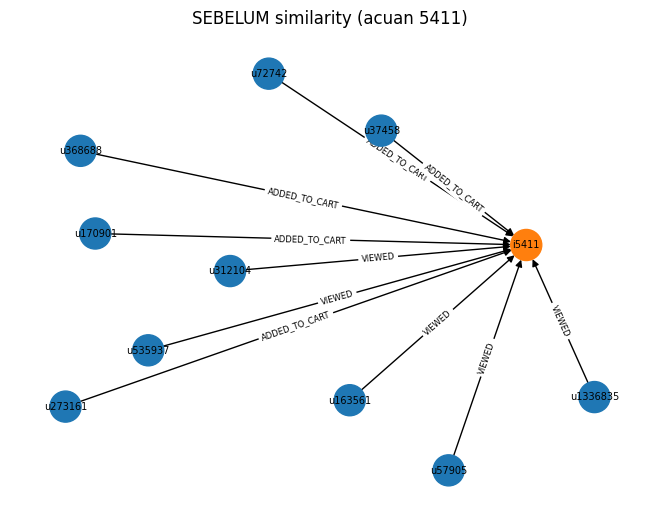

SEBELUM:
           relasi   jumlah
0  ADDED_TO_CART    41756
1         BOUGHT    13575
2         VIEWED  1605906 

SESUDAH:
           relasi   jumlah
0  ADDED_TO_CART    41756
1         BOUGHT    13575
2     SIMILAR_TO       15
3         VIEWED  1605906


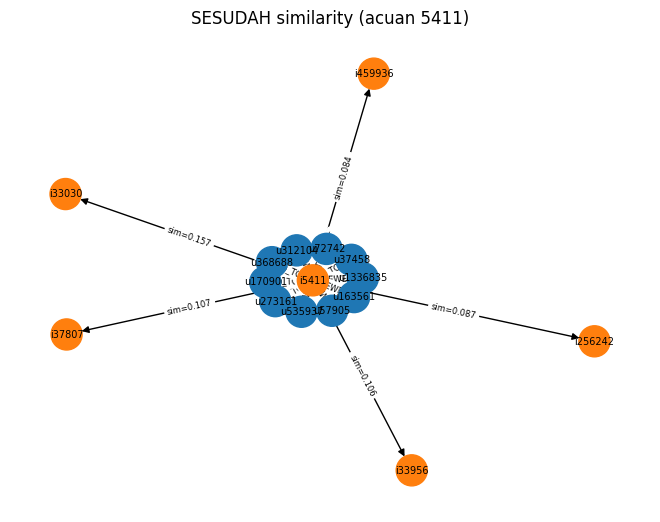

In [26]:
# [DB]
before_rels = q("MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah ORDER BY relasi")
draw_edges(neighborhood_edges(REFS[0], False), f"SEBELUM similarity (acuan {REFS[0]})")

WRITE = (f"UNWIND $rows AS r MATCH (a:{ENT['label']} {{{ENT['key']}: r.a}}), (b:{ENT['label']} {{{ENT['key']}: r.b}}) "
         "MERGE (a)-[s:SIMILAR_TO]->(b) SET s.score = r.score, s.metric = 'cosine'")
driver.execute_query(WRITE, {"rows": sim_rows}, database_=DB)

after_rels = q("MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah ORDER BY relasi")
print("SEBELUM:\n", before_rels, "\n\nSESUDAH:\n", after_rels)
draw_edges(neighborhood_edges(REFS[0], True), f"SESUDAH similarity (acuan {REFS[0]})")

In [27]:
# [DB]
L, K = ENT["label"], ENT["key"]
Q7A = f"MATCH (a:{L} {{{K}: $ref}})-[s:SIMILAR_TO]->(b:{L}) RETURN a.{K} AS acuan, b.{K} AS tetangga, s.score AS similarity ORDER BY similarity DESC LIMIT 5"
print("Cypher 7a/7b:\n", Q7A)
print(q(Q7A, ref=REFS[0]))
print(q(f"MATCH (a:{L})-[s:SIMILAR_TO]->(b:{L}) RETURN a.{K} AS a, b.{K} AS b, s.score AS similarity ORDER BY similarity DESC LIMIT 5"))

Cypher 7a/7b:
 MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item) RETURN a.itemId AS acuan, b.itemId AS tetangga, s.score AS similarity ORDER BY similarity DESC LIMIT 5
   acuan  tetangga  similarity
0   5411     33030    0.157145
1   5411     37807    0.107413
2   5411     33956    0.105582
3   5411    256242    0.087039
4   5411    459936    0.084171
        a       b  similarity
0  219512  383416    0.333063
1  219512  283919    0.328620
2  219512    1976    0.323987
3  219512  367690    0.323557
4  219512   97565    0.322149


## H. Analytics 2.2: pilih user acak (reproducible), KNN k=5, Hit@5, NDCG@5
1. Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi), lalu

    (a) tuliskan skrip Python dalam merekomendasikan KNN-nya!

    (b) berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya!


2. Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah:

    (a) Hit@5

    (b) NDCG@5

- Relevansi = item yang berinteraksi di fold testing, **dikurangi** item yang sudah dilihat di training, dan hanya yang ada di katalog training (item lain mustahil direkomendasikan).
- Kelayakan user (ditetapkan sebelum melihat hasil): minimal 3 item distinct di training dan minimal 1 item relevan.
- KNN: jika `PROJ="item"` -> item-based (k=5 tetangga per item riwayat); jika `"user"` -> user-based (k=5 tetangga user).
- Item yang sudah pernah berinteraksi di training dibuang dari rekomendasi.

In [28]:
REL_EVENTS = None   # None = semua event testing; atau ("addtocart", "transaction") untuk relevansi yang lebih ketat
tcol = test if REL_EVENTS is None else test[test.event.isin(REL_EVENTS)]
test_items = tcol.groupby("visitorid").itemid.agg(set)
item_set = set(items.tolist())
u_pos = pd.Series(np.arange(len(users)), index=users)

def seen_items(uid):
    k = u_pos[uid]; return set(items[M.indices[M.indptr[k]:M.indptr[k + 1]]].tolist())

def relevant(uid):
    return ({i for i in test_items.get(uid, set()) if i in item_set}) - seen_items(uid)

cand = sorted(set(users[du >= 3].tolist()) & set(test_items.index.tolist()))
eligible = [u for u in cand if relevant(u)]
print(f"kandidat={len(cand)} | layak={len(eligible)}")

user = int(np.random.default_rng(SEED).choice(eligible))   # reproducible: daftar terurut + seed tetap
print("User terpilih:", user, "| item di training:", len(seen_items(user)), "| item relevan di testing:", len(relevant(user)))

kandidat=4161 | layak=3376
User terpilih: 136179 | item di training: 5 | item relevan di testing: 2


In [29]:
Mn = normalize(M)
Xn = normalize(M.T.tocsr()); XnT = Xn.T.tocsr()
pop_order = np.argsort(-di, kind="stable")

def recommend(uid, k=5, n=5):
    ui_ = u_pos[uid]; row = M.getrow(ui_); H, wts = row.indices, row.data
    if PROJ == "user":
        s_ = (Mn @ Mn[ui_].T).toarray().ravel(); s_[ui_] = -1
        nn = np.argpartition(-s_, k)[:k]; nn = nn[s_[nn] > 0]
        scores = np.asarray(M[nn].T @ s_[nn]).ravel()
    else:
        scores = np.zeros(M.shape[1])
        for h, w in zip(H, wts):
            s_ = (Xn[h] @ XnT).toarray().ravel(); s_[h] = -1
            nn = np.argpartition(-s_, k)[:k]; nn = nn[s_[nn] > 0]
            scores[nn] += w * s_[nn]
    scores[H] = -np.inf                                   # buang item yang sudah berinteraksi
    top = [j for j in np.argsort(-scores, kind="stable")[:n] if scores[j] > 0]
    rec = [(int(items[j]), float(scores[j]), "knn") for j in top]
    for j in pop_order:                                   # fallback popularitas bila KNN < n (dilaporkan)
        if len(rec) >= n: break
        if j not in H and int(items[j]) not in {r[0] for r in rec}:
            rec.append((int(items[j]), 0.0, "popularitas"))
    return rec

rec = recommend(user, k=5, n=5)
print(pd.DataFrame(rec, columns=["itemid", "skor", "sumber"]))
print("3 item yang diiklankan (soal 1b):", [r[0] for r in rec[:3]])

   itemid      skor sumber
0  151677  0.373718    knn
1  169890  0.373718    knn
2  346772  0.373718    knn
3  199408  0.362987    knn
4  181687  0.360421    knn
3 item yang diiklankan (soal 1b): [151677, 169890, 346772]


Dari 5 item tersebut, 3 item teratas yang direkomendasikan sesuai soal 1b adalah:
151677, 169890, dan 346772

Nilai skor menunjukkan tingkat kedekatan/kemiripan berdasarkan hasil KNN. Semakin tinggi skor, semakin dekat item tersebut dengan pola yang digunakan oleh model.

In [30]:
def hit_at_k(rec_ids, rel, k=5):
    return int(len(set(rec_ids[:k]) & rel) > 0)

def ndcg_at_k(rec_ids, rel, k=5):
    dcg = sum(1 / math.log2(i + 2) for i, x in enumerate(rec_ids[:k]) if x in rel)
    idcg = sum(1 / math.log2(i + 2) for i in range(min(k, len(rel))))
    return dcg / idcg if idcg else 0.0

rel = relevant(user); rec_ids = [r[0] for r in rec]
print("Relevan (contoh):", sorted(rel)[:10], "| total:", len(rel))
print("Hit@5  =", hit_at_k(rec_ids, rel))
print("NDCG@5 =", round(ndcg_at_k(rec_ids, rel), 4))
print("Posisi hit:", [(i + 1, x) for i, x in enumerate(rec_ids) if x in rel])

Relevan (contoh): [42546, 448899] | total: 2
Hit@5  = 0
NDCG@5 = 0.0
Posisi hit: []


Berdasarkan data relevansi pada data testing/P2, terdapat 2 item yang dianggap relevan untuk user yang dipilih, yaitu:
- 42546
- 448899
Jadi, kedua item tersebut digunakan sebagai ground truth untuk mengevaluasi apakah rekomendasi KNN berhasil menemukan item yang relevan.

Hit@5 = 0 berarti tidak ada satu pun dari 5 item yang direkomendasikan KNN yang termasuk ke dalam 2 item relevan.
NDCG@5 = 0 berarti tidak ada item relevan yang muncul dalam Top-5, maka tidak ada item yang mendapatkan kontribusi terhadap nilai DCG.

Kesimpulan :

Berdasarkan hasil evaluasi, KNN menghasilkan 5 rekomendasi dengan tiga rekomendasi teratas yaitu item 151677, 169890, dan 346772. Namun, dari 5 item yang direkomendasikan tidak terdapat item yang termasuk dalam 2 item relevan pada data testing, yaitu 42546 dan 448899. Oleh karena itu, diperoleh nilai Hit@5 = 0 dan NDCG@5 = 0.0, serta tidak terdapat posisi hit. Hal ini menunjukkan bahwa pada user yang dipilih, rekomendasi KNN belum berhasil menemukan item yang relevan pada data testing.

### Evaluasi tambahan : rata-rata atas 200 user


In [31]:
sample = np.random.default_rng(SEED).choice(eligible, size=min(200, len(eligible)), replace=False)
res = []
for u in tqdm(sample):
    ids = [r[0] for r in recommend(int(u))]; rl = relevant(int(u))
    res.append((hit_at_k(ids, rl), ndcg_at_k(ids, rl)))
res = np.array(res); print(f"n={len(res)} | Hit@5 rata-rata={res[:, 0].mean():.3f} | NDCG@5 rata-rata={res[:, 1].mean():.3f}")

  0%|          | 0/200 [00:00<?, ?it/s]

n=200 | Hit@5 rata-rata=0.010 | NDCG@5 rata-rata=0.002


In [32]:
# [DB]
driver.close()